# Variational Quantum Eigensolver for Two Capacitively Coupled Transmons

This notebook follows the four implementation steps in Section 3 of `vqe.ipynb`. `Coursework_1.ipynb` is the coding-style reference.

| Procedure | Notebook section |
|---|---|
| 3.1 Step 1 | Build the two-transmon charge Hamiltonian, map it to Pauli strings, compute the exact reference energy, and construct the ansatz. |
| 3.2 Step 2 | Select a local target, transpile the circuit, and apply the layout to the observable. |
| 3.3 Step 3 | Define the Estimator cost, initialize the angles, and run COBYLA. |
| 3.4 Step 4 | Compare the energies, distinguish ansatz error from optimizer error, and plot convergence. |

**Assumptions and deviations**

- The circuit has two capacitively shunted Josephson junctions linked by a direct coupling capacitor. The default charging energies divided by $h$ are $0.25$ and $0.24$ GHz, and the Josephson energies divided by $h$ are $12.5$ and $13.2$ GHz. Both offset charges are zero. Each charge basis runs from $-5$ to $5$.
- The coupling coefficient is $g_C=0.18$ GHz in the term $g_C\hat n_1\hat n_2$. It is a coefficient in the charge Hamiltonian. The exchange matrix element between particular transmon levels also depends on their charge matrix elements.
- The ansatz replaces `efficient_su2` with real rotations in the even-parity sector of the four lowest local levels per transmon. It starts near the uncoupled product ground state, with seeded random perturbations. The cost still uses the full charge-basis Pauli Hamiltonian.
- A local all-to-all target and noiseless `StatevectorEstimator` replace live backend selection and finite-shot execution. The transpiled circuit is summarized by gate counts and depth.
- The convergence plot uses optimizer callbacks. Trial evaluations are counted separately.

The first code cell loads the tested libraries. The second prints the two transmon ratios and the coupling coefficient.

In [3]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
import matplotlib.pyplot as plt
import numpy as np
import time
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RYGate, UnitaryGate
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

In [4]:
# Effective circuit energies divided by h [GHz]
E_C1, E_C2 = 0.25, 0.24
E_J1, E_J2 = 12.50, 13.20
g_C = 0.18  # Coefficient of n1 * n2 [GHz]

# Both offset charges are fixed at zero for the parity-based ansatz.
N = 5  # Shared charge cutoff [integer number of Cooper pairs]

# Reproducibility and COBYLA settings
seed = 42
max_evals = 1200
initial_radius = 0.05  # Initial trust-region radius [radians]
optimizer_tol = 1e-7   # Final trust-region radius [radians]

assert isinstance(N, int) and N >= 2  # At least four local levels.
assert np.all(np.isfinite([E_C1, E_C2, E_J1, E_J2, g_C]))
assert min(E_C1, E_C2, E_J1, E_J2) > 0
assert 0 <= g_C < 8 * np.sqrt(E_C1 * E_C2)  # Positive charging form.

print(f"E_J1 / E_C1 = {E_J1 / E_C1:g}")
print(f"E_J2 / E_C2 = {E_J2 / E_C2:g}")
print(f"Charge coupling coefficient = {g_C:.3f} GHz")

E_J1 / E_C1 = 50
E_J2 / E_C2 = 55
Charge coupling coefficient = 0.180 GHz


### 3.1 Step 1: Map the problem to quantum circuits and operators

Use frequency units throughout, so $H$, $E_{Ci}$, and $E_{Ji}$ below denote energies divided by $h$. At zero offset charge,

$$
H=\sum_{i=1}^2\left[4E_{Ci}\hat n_i^2-E_{Ji}\cos\hat\phi_i\right]
  +g_C\hat n_1\hat n_2.
$$

The charging and coupling terms are diagonal in $|n_1,n_2\rangle$. The coupling comes from the off-diagonal element of the inverse capacitance matrix and makes the electrostatic energy depend on both island charges. Each Josephson term transfers one Cooper pair across its own junction, producing matrix elements $-E_{Ji}/2$ between neighbouring charges on that island. [*Superconducting Circuit Companion*, coupled-transmon example](https://doi.org/10.1103/PRXQuantum.2.040204)

Each register encodes $j_i=n_i+N$ using $q=\lceil\log_2(2N+1)\rceil$ qubits. Register 1 holds the low bits, so the combined computational index is $2^q j_2+j_1$. A state is padding if either register's index exceeds $2N$. The physical block has zero coupling to padding, whose energy is set above the lowest physical diagonal entry. By the variational principle, this puts the padding above the physical ground energy.

Expect a $121\times121$ physical Hamiltonian, eight qubits, and a reconstruction check on the embedded matrix $A=\sum_P c_P P$.

In [5]:
# Check time for VQE execution
import time
start = time.perf_counter()


def local_hamiltonian(E_C, E_J, N):
    """Return a zero-offset transmon Hamiltonian [GHz] and charge operator."""
    n = np.arange(-N, N + 1)  # Charge in units of 2e [dimensionless].
    charging = 4 * E_C * n**2  # Electrostatic energy of the island [GHz].

    # A Josephson tunnelling event moves the charge by one Cooper pair.
    hopping = np.full(n.size - 1, -E_J / 2)  # [GHz]
    H_local = np.diag(charging) + np.diag(hopping, 1) + np.diag(hopping, -1)
    return H_local, np.diag(n)


H1, Q1 = local_hamiltonian(E_C1, E_J1, N)
H2, Q2 = local_hamiltonian(E_C2, E_J2, N)
d = H1.shape[0]
q = int(d - 1).bit_length()  # Qubits per transmon.
D = 2**q
num_qubits = 2 * q
I = np.eye(d)

# Register 1 varies fastest, so transmon 2 is the left Kronecker factor.
H_uncoupled = np.kron(I, H1) + np.kron(H2, I)
H = H_uncoupled + g_C * np.kron(Q2, Q1)

# Keep the physical charge states in tensor-product order when embedding H.
j = np.arange(d)
physical = (D * j[:, None] + j[None, :]).ravel()
E_pad = np.diag(H).min() + E_J1 + E_J2  # Padding energy [GHz]
A = E_pad * np.eye(D**2)
A[np.ix_(physical, physical)] = H

# Check the entire embedding, including the zero couplings to padding.
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-12, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-10, rtol=0)

print(f"Physical Hamiltonian: {H.shape}")
print(f"{num_qubits} qubits, {D**2 - d**2} padding states")
print(f"Pauli reconstruction passed ({len(hamiltonian)} terms).")

Physical Hamiltonian: (121, 121)
8 qubits, 135 padding states
Pauli reconstruction passed (1280 terms).


#### Exact reference energy

Diagonalize the full physical charge matrix $H$ with NumPy. This benchmark includes the coupling and all retained charge states. Expect a ground energy of about $-20.81354928$ GHz. The coupled eigenvalues are used for validation only.

In [6]:
# Diagonalize the physical block so the reference excludes padding.
eigenvalues = np.linalg.eigvalsh(H)
E_exact = float(eigenvalues[0])  # Ground-state energy divided by h [GHz].
print(f"Exact ground-state energy = {E_exact:.12f} GHz")

Exact ground-state energy = -20.813549280434 GHz


#### Ansatz

At zero offset charge, the Hamiltonian is invariant under simultaneous reflection $(n_1,n_2)\mapsto(-n_1,-n_2)$. The ground state is even under this reflection. The individual charge reflections are broken by the coupling, so the ansatz must allow both even–even and odd–odd pairs of local levels. In particular, it can mix the uncoupled ground state $|0,0\rangle$ with $|1,1\rangle$.

Diagonalize the two local matrices $H_1$ and $H_2$ separately to define their level bases. Among the first four levels of each, eight pairs have even total parity. Seven two-state rotations prepare an arbitrary real normalized vector over those eight pairs. A CX copies the local parity bit to the second register, and fixed local unitaries convert both registers back to charge coordinates. The circuit therefore evaluates the original charge-basis observable while restricting the trial states to the chosen local levels.

Expect seven angles and eight encoded qubits. The local eigendecompositions supply basis vectors for the ansatz. The coupled eigendecomposition from the previous cell plays no role in preparing it.

In [7]:
local_e1, local_v1 = np.linalg.eigh(H1)
local_e2, local_v2 = np.linalg.eigh(H2)

# Check that the low bit of each local level index represents its parity.
parity_signs = np.array([1, -1, 1, -1])
for vectors in (local_v1, local_v2):
    assert np.allclose(
        vectors[::-1, :4], vectors[:, :4] * parity_signs, atol=1e-9, rtol=0
    )

prep = QuantumCircuit(3)
theta = ParameterVector("theta", 7)  # Rotation angles [radians].

# Rotate |000> into each other basis state in turn. The CX gates map
# |k> to a single set bit so a controlled RY acts only on the desired pair.
for k in range(1, 8):
    set_bits = [bit for bit in range(3) if k & (1 << bit)]
    pivot, *targets = set_bits
    controls = [bit for bit in range(3) if bit != pivot]

    for bit in targets:
        prep.cx(pivot, bit)
    rotation = RYGate(theta[k - 1]).control(2, ctrl_state=0)
    prep.append(rotation, [*controls, pivot])
    for bit in reversed(targets):
        prep.cx(pivot, bit)

ansatz = QuantumCircuit(num_qubits)
ansatz.compose(prep, qubits=[0, 1, q + 1], inplace=True)
ansatz.cx(0, q)  # Equal local parity bits give even total parity.

# Column k of each basis change is the charge wavefunction of local level k.
for start, vectors in ((0, local_v1), (q, local_v2)):
    basis_change = np.eye(D)
    basis_change[:d, :d] = vectors
    gate = UnitaryGate(basis_change, label="Level to charge")
    ansatz.append(gate, range(start, start + q))

num_params = ansatz.num_parameters
print(f"Ansatz: {num_params} parameters on {num_qubits} qubits")

Ansatz: 7 parameters on 8 qubits


### 3.2 Step 2: Optimize for target hardware

Define an eight-qubit local target with all-to-all connectivity. This keeps the focus on compiling the local basis-change unitaries and controlled rotations into `u` and `cx` gates. Expect a summary of the target's operations. [Qiskit `GenericBackendV2` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.providers.fake_provider.GenericBackendV2)

In [8]:
# With no coupling map supplied, GenericBackendV2 connects every qubit pair.
backend = GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["u", "cx"],
    seed=seed,
    noise_info=False,
)
target = backend.target
print(f"Local target: {target.num_qubits} qubits, operations {backend.operation_names}")

Local target: 8 qubits, operations ['u', 'cx', 'reset', 'delay', 'measure']


#### Transpile the ansatz

Compile the trial circuit once, before the optimizer evaluates any angles. Expect the circuit depth and gate counts. The gate counts show the cost of translating the fixed local basis changes into native gates.

In [9]:
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
ansatz_isa = pm.run(ansatz)
assert set(ansatz_isa.parameters) == set(ansatz.parameters)

print(f"Transpiled depth: {ansatz_isa.depth()}")
print(f"Transpiled gate counts: {dict(ansatz_isa.count_ops())}")

Transpiled depth: 286
Transpiled gate counts: {'u': 388, 'cx': 257}


#### Apply the layout to the Hamiltonian

Use the circuit's final layout to place the Pauli operators on the corresponding output wires. Expect a list mapping each logical qubit to its final wire.

In [10]:
hamiltonian_isa = hamiltonian.apply_layout(ansatz_isa.layout)
assert hamiltonian_isa.num_qubits == ansatz_isa.num_qubits
print(f"Logical-to-final qubits: {ansatz_isa.layout.final_index_layout()}")

Logical-to-final qubits: [1, 2, 6, 7, 3, 0, 4, 5]


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values

The local Estimator evaluates the energy $\langle\psi(\vec{\theta})|A|\psi(\vec{\theta})\rangle$ with no shot noise. Each trial energy is bounded below by the exact ground energy, up to numerical precision. The cost function stores every evaluation, and the callback stores the optimizer's reported iterations. The next cell defines both functions and prints nothing. [Qiskit `StatevectorEstimator` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [11]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return and record the energy of one trial [GHz]."""
    pub = (ansatz, hamiltonian, params)
    energy = float(estimator.run([pub]).result()[0].data.evs.item())
    cost_history_dict["cost_history"].append(energy)
    return energy


def record_iteration(intermediate_result):
    """Record COBYLA's iteration energy [GHz] without another Estimator call."""
    cost_history_dict["iters"].append(intermediate_result.nit)
    cost_history_dict["iteration_energy"].append(float(intermediate_result.fun))


cost_history_dict = {"cost_history": [], "iters": [], "iteration_energy": []}

#### Initial parameters

Zero angles give the product of the two local ground states. Start with small seeded perturbations around that point because the default coupling is weak. Expect seven initial angles.

In [12]:
rng = np.random.default_rng(seed)
x0 = rng.normal(loc=0.0, scale=0.02, size=num_params)  # Angles [radians].
print(f"Initialised {x0.size} angles near the uncoupled ground state.")

Initialised 7 angles near the uncoupled ground state.


#### Run the classical optimizer

COBYLA updates the angles using the energy evaluations. Its `maxiter` option caps objective evaluations in the pinned SciPy version. The execution cell stores the solution in `res`. The next cell prints the termination message, energy, and evaluation count. [SciPy COBYLA documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/optimize.minimize-cobyla.html)

In [13]:
# Clear old histories so rerunning this cell starts a fresh optimization.
for history in cost_history_dict.values():
    history.clear()

estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa, hamiltonian_isa, estimator),
    method="COBYLA",
    callback=record_iteration,
    options={
        "maxiter": max_evals,
        "rhobeg": initial_radius,
        "tol": optimizer_tol,
    },
)

In [19]:
print(res)
# Cell where the algorithm ends
end = time.perf_counter()
print(f"Elapsed: {(end - start)*10**-9:.4f} s")

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -20.813549146475154
       x: [-4.600e-02  1.534e-03  9.368e-04  1.517e-03  8.827e-04
            1.070e-03 -4.448e-05]
    nfev: 186
   maxcv: 0.0
Elapsed: 0.0005 s


### 3.4 Step 4: Post-process results

Compare the VQE energy with the full charge-basis result. Then diagonalize $V^\mathsf{T}HV$, where the columns of $V$ are the eight product states accessible to the ansatz. This gives the best energy the circuit can reach within its level restriction. The gap between that energy and the full charge result measures the ansatz restriction. The gap between VQE and the projected result measures the residual optimization error to numerical precision.

As a coupling check, compare the exact coupled energy with the sum of the two local ground energies. The default coupling should lower the ground energy by about $5.03$ MHz. Expect zero padding occupation in the logical trial circuit and agreement between the logical energy and the transpiled Estimator result.

In [15]:
assert len(cost_history_dict["cost_history"]) == res.nfev
E_vqe = float(res.fun)  # [GHz]
absolute_error = abs(E_vqe - E_exact)  # [GHz]

# The ansatz includes the local level pairs whose parity bits agree.
pairs = [(i, j) for j in range(4) for i in range(4) if (i + j) % 2 == 0]
V = np.column_stack([
    np.kron(local_v2[:, j], local_v1[:, i]) for i, j in pairs
])
E_subspace = float(np.linalg.eigvalsh(V.T @ H @ V)[0])  # [GHz]

# Recover the logical state to check padding and the layout-adjusted energy.
params_opt = dict(zip(ansatz_isa.parameters, res.x))
psi_opt = Statevector.from_instruction(ansatz.assign_parameters(params_opt))
padding = np.ones(D**2, dtype=bool)
padding[physical] = False
p_pad = float(np.sum(np.abs(psi_opt.data[padding])**2))
E_logical = float(np.vdot(psi_opt.data, A @ psi_opt.data).real)  # [GHz]

assert np.isclose(E_logical, E_vqe, atol=1e-9, rtol=0)
assert E_exact <= E_subspace + 1e-9
assert E_subspace <= E_vqe + 1e-9

# In the uncoupled limit the ground-state energies add.
E_uncoupled = float(local_e1[0] + local_e2[0])  # [GHz]
assert np.isclose(np.linalg.eigvalsh(H_uncoupled)[0], E_uncoupled, atol=1e-10)
coupling_shift = E_exact - E_uncoupled  # [GHz]

print(f"Exact coupled energy:    {E_exact:.12f} GHz")
print(f"Best ansatz energy:      {E_subspace:.12f} GHz")
print(f"VQE energy:              {E_vqe:.12f} GHz")
print(f"Absolute VQE error:      {absolute_error:.3e} GHz")
print(f"Ansatz restriction:      {E_subspace - E_exact:.3e} GHz")
print(f"Optimizer residual:      {abs(E_vqe - E_subspace):.3e} GHz")
print(f"Padding probability:     {p_pad:.3e}")
print(f"Coupling-induced shift:  {1000 * coupling_shift:.6f} MHz")

Exact coupled energy:    -20.813549280434 GHz
Best ansatz energy:      -20.813549146475 GHz
VQE energy:              -20.813549146475 GHz
Absolute VQE error:      1.340e-07 GHz
Ansatz restriction:      1.340e-07 GHz
Optimizer residual:      1.386e-13 GHz
Padding probability:     0.000e+00
Coupling-induced shift:  -5.031569 MHz


#### Convergence plot

Plot the callback energy against the COBYLA iteration number. Expect the energy to fall towards the dashed exact ground-energy line. At this scale, the residual gap is too small to distinguish visually.

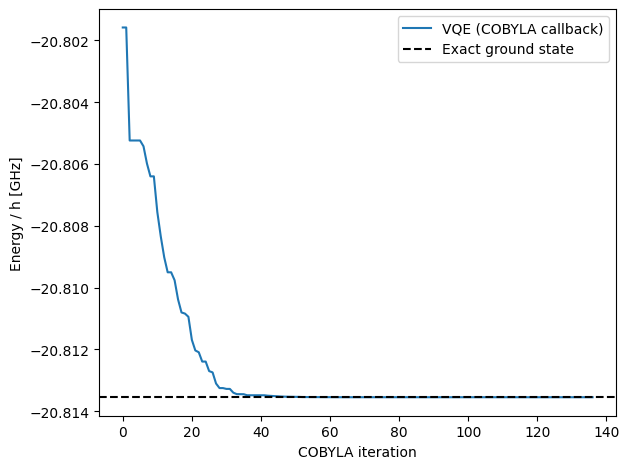

In [16]:
fig, ax = plt.subplots()
ax.plot(
    cost_history_dict["iters"],
    cost_history_dict["iteration_energy"],
    label="VQE (COBYLA callback)",
)
ax.axhline(E_exact, color="black", linestyle="--", label="Exact ground state")
ax.set_xlabel("COBYLA iteration")
ax.set_ylabel("Energy / h [GHz]")
ax.legend()
fig.tight_layout()
plt.show()

## Results and limitations

COBYLA converged in 186 objective evaluations with the default parameters and tested library versions.

| Quantity | Tested value |
|---|---:|
| Exact coupled ground energy divided by $h$ | $-20.813549280434$ GHz |
| Best energy in the ansatz subspace divided by $h$ | $-20.813549146475$ GHz |
| VQE ground energy divided by $h$ | $-20.813549146475$ GHz |
| Absolute VQE error | $1.34\times10^{-7}$ GHz, about $134$ Hz |
| Exact coupling-induced energy shift | $-5.032$ MHz |
| Logical padding probability | $0$ |

The projected result shows that the four-local-level restriction accounts for nearly all of the VQE error at fixed cutoff. In a separate exact calculation, raising the cutoff from $N=5$ to $N=7$ lowered the ground energy by about $83.3$ kHz. For these defaults, the charge cutoff matters more than either the ansatz restriction or the optimizer residual.

The parity construction assumes zero offset charges. Stronger coupling can require more local levels. The dense basis-change circuits and noiseless Estimator make this a local VQE demonstration. The tested circuit used 257 CX gates after transpilation, and the reported energies carry no hardware noise or shot uncertainty.